In [ ]:
from primitives import Point, Line, GeometrySceneDG, HPP, VPP

# Create a simple scene
scene = GeometrySceneDG()

# Create points
point_A = Point(-10, -10, -10)('A')
point_B = Point(1, 2, 3)('B')
point_C = Point(5, 5, 5)('C')

# Calculate distance (AB)
distance = point_A.distance(point_B)
print(f"Distance between A and B: {distance}")

# Calculate distance (AC)
distance = point_A.distance(point_C)
print(f"Distance between A and C: {distance}")

# Create lines
line_AB = (point_A ^ point_B)('AB')
line_AC = (point_A ^ point_C)('AC')
print(f"Line AB: {line_AB}")
print(f"Line AC: {line_AC}")

# 3D view (right)
point_A.plot()
point_B.plot()
point_C.plot()
line_AB.plot()
line_AC.plot()

# 2D view - horizontal projections (left)
(point_A @ HPP).plot_hp()
(point_B @ HPP).plot_hp()
(point_C @ HPP).plot_hp()
(line_AB @ HPP).plot_hp()
(line_AC @ HPP).plot_hp()

In [ ]:
import importlib
import primitives
importlib.reload(primitives)

from primitives import Cylinder, exporters

# Create cylinder: height=50mm, diameter=30mm
cylinder = Cylinder(height=50, diameter=30)
print(cylinder.str_en())
print(f"origin={cylinder.origin}, end={cylinder.end}, radius={cylinder.radius}")

# Display in OCP CAD Viewer (falls back to matplotlib if not available)
cylinder.show_model(port=3939)
cylinder.preview()  # Plot horizontal projection
# Keep reference for next cell (hole)
cq_model = cylinder.to_cq()

# 2D visualization from cadquery
cylinder._plot_2d_cq()

# Export to STL and 3MF in the current folder
exporters.export(cq_model, 'cylinder.stl')
print("STL saved: cylinder.stl")

exporters.export(cq_model, 'cylinder.3mf')
print("3MF saved: cylinder.3mf")


In [ ]:
import importlib
import primitives
importlib.reload(primitives)

from primitives import ocp_show, ocp_set_port, exporters

# Add axial hole through the cylinder center
hole_diameter = 10  # mm

cq_model_with_hole = cq_model.faces("<X").workplane().hole(hole_diameter)

print(f"Hole drilled: diameter={hole_diameter}mm through cylinder axis")

ocp_set_port(3939)
ocp_show(cq_model_with_hole)

'''
exporters.export(cq_model_with_hole, 'cylinder_with_hole.step')
print("STEP saved: cylinder_with_hole.step")
'''

In [ ]:
import importlib
import primitives
importlib.reload(primitives)
import cadquery as cq

from primitives import ocp_show, ocp_set_port, exporters

# Add axial hole through the cylinder center
hole_diameter = 10  # mm

cq_model_with_hole = cq_model.faces("<X").workplane().hole(hole_diameter)

print(f"Hole drilled: diameter={hole_diameter}mm through cylinder axis")

ocp_set_port(3939)
ocp_show(cq_model_with_hole)

'''
exporters.export(cq_model_with_hole, 'cylinder_with_hole.step')
print("STEP saved: cylinder_with_hole.step")
'''

In [ ]:
import importlib
import primitives
importlib.reload(primitives)

from primitives import ocp_show, ocp_set_port
#import cadquery as cq

hole_diameter = 10

# Midpoint along the cylinder axis (X)
midpoint_x = cylinder.origin + cylinder.height / 2

# XZ plane is perpendicular to Y — cut through in both Y directions
cutter = (
    cq.Workplane("XZ")
    .center(midpoint_x, 0)
    .circle(hole_diameter / 2)
    .extrude(cylinder.radius + 1, both=True)
)

cq_model_y_hole = cylinder.to_cq().cut(cutter)

print(f"Hole along Y axis at x={midpoint_x}mm, diameter={hole_diameter}mm")

ocp_set_port(3939)
ocp_show(cq_model_y_hole)

In [ ]:
import sys
sys.modules.pop('primitives', None)
import primitives

from primitives import Cylinder, ComposedPart

cyl1 = Cylinder(height=50, diameter=30)
cyl2 = Cylinder(height=40, diameter=20)

# Place cyl2 perpendicular (rotate 90° around Y, centered at midpoint of cyl1)
midpoint_x = cyl1.origin + cyl1.height / 2

def place_perpendicular(shape):
    return shape.rotate((0, 0, 0), (0, 1, 0), 90).translate((midpoint_x, 0, 0))

part = ComposedPart(cyl1, cyl2)
part.show_model(port=3939, transforms=[None, place_perpendicular])

In [5]:

import primitives

from primitives import Cylinder, ComposedPart

# Outer cylinder
cyl_outer = Cylinder(height=50, diameter=30)
# Inner cylinder — slightly longer so the cut goes fully through both end caps
cyl_inner = Cylinder(height=50, diameter=20)

def center_inner(shape):
    return shape.translate((0, 0, 0))

part = ComposedPart(cyl_outer, cyl_inner)
part.preview()
part.show_model(port=3939, transforms=[None, center_inner], operations=['cut'])

(0, Cylinder(50, 30)) (1, Cylinder(50, 20))
[<matplotlib.lines.Line2D object at 0x123f29190>, <matplotlib.lines.Line2D object at 0x123cd9cd0>]
[<matplotlib.lines.Line2D object at 0x123cb0e50>, <matplotlib.lines.Line2D object at 0x123cdec10>]
c


In [8]:
import sys
sys.modules.pop('primitives', None)
import primitives
import reportlab
from primitives import Cylinder, Node, GeometryScene, exporters

cyl_a = Cylinder(height=50, diameter=30)
cyl_b = Cylinder(height=40, diameter=20)
cyl_c = Cylinder(height=30, diameter=15)
cyl_hole = Cylinder(height=52, diameter=10)

# ── Example 1: nodes dict + position/rotation as properties ──────────────────
print("=== Example 1: inspect nodes dict ===")
part = cyl_a + cyl_b + cyl_c - cyl_hole
print("Part nodes: " + str(part.nodes))
# Inspect and mutate a node's position directly
n1 = part.nodes[1]
print("node 1 before:", n1.position)
n1.position = (40, 0, 0)
print("node 1 after:  ", n1.position)
n2 = part.nodes[2]
n2.position = (80, 0, 0)
n3 = part.nodes[3]
n3.position = (58, 0, 0)

GeometryScene()
part.preview()
part.show_model(port=3939)
exporters.export(part.to_cq(), 'part.stl')

from primitives import ModelDoc
doc = ModelDoc(part)
doc()   # displays HTML table in Jupyter, plain text in terminal
doc.to_pdf("model_doc.pdf")  


ModuleNotFoundError: No module named 'reportlab'

In [ ]:
‹››

[<matplotlib.lines.Line2D object at 0x130d6df10>, <matplotlib.lines.Line2D object at 0x130d61100>]


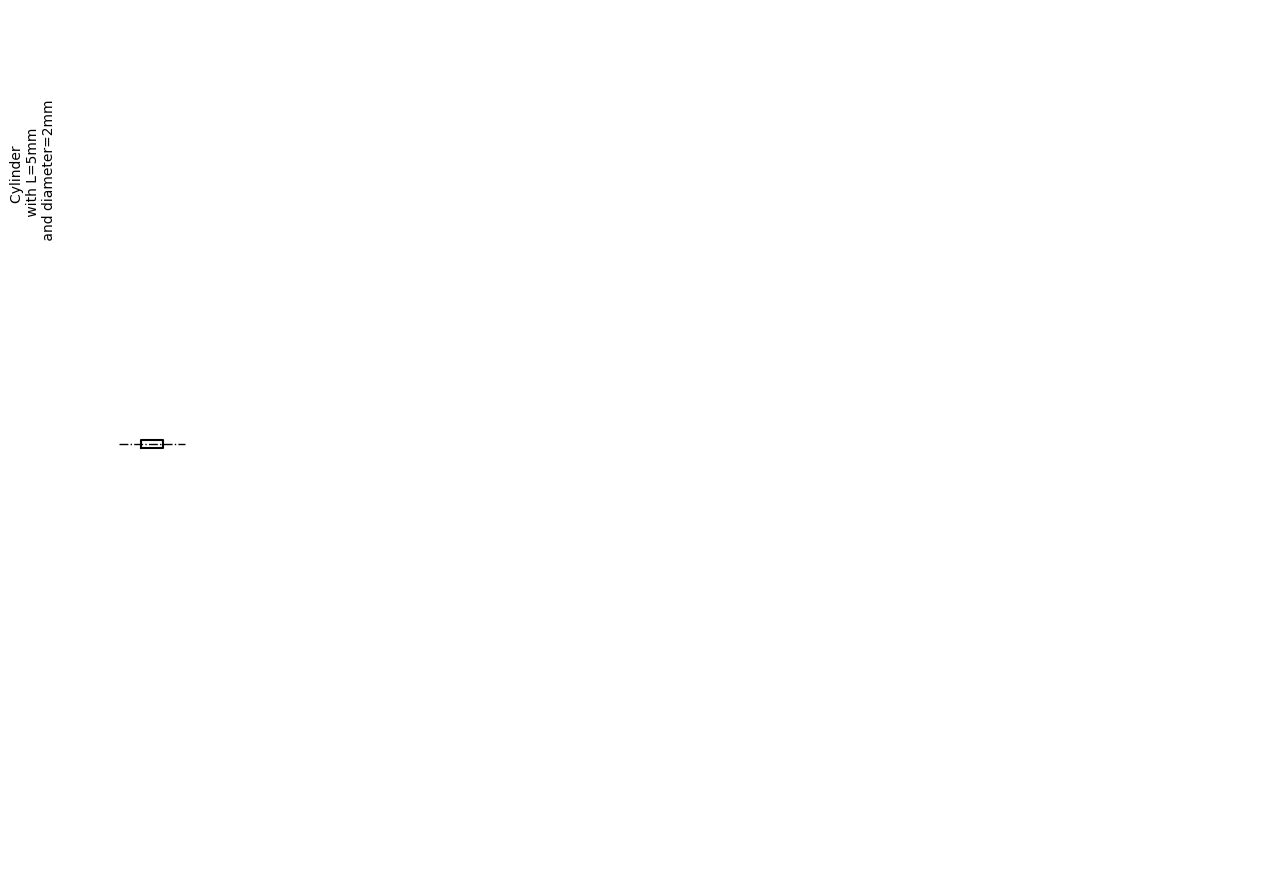

In [3]:
import matplotlib.pyplot as plt
from primitives import Cylinder, GeometryScene

cyl = Cylinder(5, 2)
GeometryScene()
cyl._plot_2d()
plt.show()


In [4]:
import importlib
import primitives
importlib.reload(primitives)

from primitives import (
    Primitive, Point, Line, Plane, Solid, Cylinder,
    ParallelPlane, Tetragon, HorizontalPlane, FrontalPlane, VerticalPlane, LateralPlane,
    DrawingSet, GeometricalCase, Prism, TetraPrism,
    View, Section, HalfSection, FrontView,
    GeometrySceneDG, GeometryScene, Node, ComposedPart, NodeType, ShaftPreview,
)

def print_hierarchy(cls, prefix="", is_last=True, is_root=True):
    connector = "" if is_root else ("└── " if is_last else "├── ")
    bases = [b.__name__ for b in cls.__bases__ if b is not object]
    annotation = f"  ({', '.join(bases)})" if not is_root and bases else ""
    print(f"{prefix}{connector}{cls.__name__}{annotation}")
    new_prefix = prefix if is_root else (prefix + ("    " if is_last else "│   "))
    subclasses = cls.__subclasses__()
    for i, sub in enumerate(subclasses):
        print_hierarchy(sub, new_prefix, i == len(subclasses) - 1, False)

roots = [Primitive, View, GeometrySceneDG, GeometryScene, Node, ComposedPart, NodeType, ShaftPreview]
for root in roots:
    print_hierarchy(root)
    print()


Primitive
├── Point  (Primitive)
├── Line  (Primitive)
├── Plane  (Primitive)
│   ├── ParallelPlane  (Plane)
│   ├── Tetragon  (Plane)
│   ├── HorizontalPlane  (Plane)
│   ├── FrontalPlane  (Plane)
│   │   └── VerticalPlane  (FrontalPlane)
│   └── LateralPlane  (Plane)
├── Solid  (Primitive)
│   └── Cylinder  (Solid)
└── DrawingSet  (Primitive, list)
    └── GeometricalCase  (DrawingSet)
        └── Prism  (GeometricalCase)
            └── TetraPrism  (Prism)

View
├── Section  (View)
├── HalfSection  (View)
└── FrontView  (View)

GeometrySceneDG

GeometryScene

Node

ComposedPart

NodeType

ShaftPreview



In [ ]:
# Skrypt umożliwiający wizualizacje walca:
                   
# Wywołanie obu bibliotek:
import matplotlib.pyplot as plt
import numpy as np

# Definicja parametrów walca:
r = 3
h = 4

# Tworzenie siatki opisującej powierzchnie walca - opis parametryczny za pomocą równań
theta = np.linspace(0, 2 * np.pi, 30)
z = np.linspace(0, h, 30)
theta, z = np.meshgrid(theta, z)
x = r * np.cos(theta)
y = r * np.sin(theta)

# Tworzenie walca
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Plot curved surface
ax.plot_surface(
    x, y, z,
    color = 'red',
    edgecolor = 'black'
)

# Tworzenie podstaw walca
circle = np.linspace(0, 2 * np.pi, 200)
x_circle = r * np.cos(circle)
y_circle = r * np.sin(circle)
ax.plot(x_circle, y_circle, np.zeros_like(circle),
        color='grey', linewidth=1.5)
ax.plot(x_circle, y_circle, np.full_like(circle, h),
        color='grey', linewidth=1.5)

# Tworzenie krawędzi walca
for angle in np.linspace(0, 2*np.pi, 8, endpoint=False):
    x_k = r * np.cos(angle)
    y_k = r * np.sin(angle)
    ax.plot(
        [x_k, x_k],
        [y_k, y_k],
        [0, h],
        color='grey'
    )

# Opisy wszystkich osi
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

# Definicja kąta widoku 
ax.view_init(elev=30, azim=35)

# Wizualizacja wyników                   
plt.tight_layout()
plt.show()

In [ ]:
import cadquery as cq

# Parametry walca
radius = 2.0
height = 5.0

# Utworzenie modelu walca
walec = (
    cq.Workplane("XY")
    .circle(radius)
    .extrude(height)
)

ocp_set_port(3939)
ocp_show(walec)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parametry walca
radius = 2
height = 5

# Utworzenie siatki punktów opisujących powierzchnię walca
theta = np.linspace(0, 2 * np.pi, 100)
z = np.linspace(0, height, 50)
theta, z = np.meshgrid(theta, z)

x = radius * np.cos(theta)
y = radius * np.sin(theta)

# Utworzenie figury
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Rysowanie powierzchni bocznej walca
ax.plot_surface(
    x, y, z,
    color='skyblue',
    edgecolor='gray',
    alpha=0.8
)

# Rysowanie górnej i dolnej podstawy (okręgów)
theta_circle = np.linspace(0, 2 * np.pi, 200)
x_circle = radius * np.cos(theta_circle)
y_circle = radius * np.sin(theta_circle)

ax.plot(x_circle, y_circle, np.zeros_like(theta_circle),
        color='black', linewidth=2)
ax.plot(x_circle, y_circle, np.full_like(theta_circle, height),
        color='black', linewidth=2)

# Rysowanie pionowych linii krawędziowych
for angle in np.linspace(0, 2*np.pi, 8, endpoint=False):
    x_edge = radius * np.cos(angle)
    y_edge = radius * np.sin(angle)
    ax.plot(
        [x_edge, x_edge],
        [y_edge, y_edge],
        [0, height],
        color='black',
        linewidth=1
    )

# Opisy osi
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Wizualizacja walca 3D")

# Zachowanie jednakowych proporcji osi
ax.set_box_aspect([1, 1, height / radius])

# Ustawienie kąta obserwacji
ax.view_init(elev=25, azim=40)

plt.tight_layout()
plt.show()

In [ ]:
import importlib, primitives; importlib.reload(primitives)
from primitives import BambuPrintPipeline
import cadquery as cq
from primitives import exporters, BambuPrintPipeline
# Get the assembled model and rotate 90° around Y → stands upright
cq_model = part.to_cq()
cq_model = cq_model.rotate((0, 0, 0), (0, 1, 0), 90)
exporters.export(cq_model, 'part.stl')

pipeline = BambuPrintPipeline(
    ip='192.168.0.73',
    access_code='f3b251fb',
    serial='03919C450202357',
)

# Pass raw STL or unsliced 3MF — pipeline auto-slices via OrcaSlicer, then uploads and prints.
pipeline('part.stl', brim_width=5)

# Optional overrides:
#pipeline('part.stl', layer_height='0.15mm', filament='Bambu PLA Basic @BBL A1', bed_leveling=True, flow_cali=True, use_ams=False)


[BambuPrint] No gcode found — slicing with OrcaSlicer ...
[BambuPrint] Sliced → part_sliced.3mf
[BambuPrint] Patched printer_model_id → N2S
[BambuPrint] Uploading part_sliced.3mf → 192.168.0.73 ...
[BambuPrint] Uploaded part_sliced.3mf + 1_part_sliced.bbl
[BambuPrint] Sending print command ...
[BambuPrint] Done — printer is starting.


In [10]:
import subprocess, ftplib, ssl, zipfile, threading, json
import paho.mqtt.client as mqtt

IP          = '192.168.0.73'
ACCESS_CODE = 'f3b251fb'
SERIAL      = '03919C450202357'
FILE        = 'cylinder.3mf'

# ── 1. Ping ───────────────────────────────────────────────────────────────────
ping = subprocess.run(['ping', '-c', '2', '-W', '1000', IP], capture_output=True, text=True)
print("1. PING:", "OK" if ping.returncode == 0 else "FAIL — printer unreachable")

# ── 2. Check if 3MF contains gcode ───────────────────────────────────────────
with zipfile.ZipFile(FILE) as z:
    names = z.namelist()
has_gcode = any('gcode' in n.lower() for n in names)
print(f"2. 3MF contents: {names}")
print(f"   Has gcode: {'YES' if has_gcode else 'NO — raw geometry, printer cannot print this without slicing first!'}")

# ── 3. FTPS port reachable? ───────────────────────────────────────────────────
import socket
try:
    s = socket.create_connection((IP, 990), timeout=5)
    s.close()
    print("3. FTPS port 990: reachable")
except Exception as e:
    print(f"3. FTPS port 990: FAIL — {e}")

# ── 4. MQTT port reachable? ───────────────────────────────────────────────────
try:
    s = socket.create_connection((IP, 8883), timeout=5)
    s.close()
    print("4. MQTT port 8883: reachable")
except Exception as e:
    print(f"4. MQTT port 8883: FAIL — {e}")

# ── 5. MQTT — listen to printer status for 5s ─────────────────────────────────
messages = []
done = threading.Event()

def on_connect(client, ud, flags, rc, props):
    client.subscribe(f"device/{SERIAL}/report")
    print(f"5. MQTT: connected, listening for printer report...")

def on_message(client, ud, msg):
    data = json.loads(msg.payload)
    messages.append(data)
    print(f"   report: {json.dumps(data, indent=2)[:400]}")
    done.set()

client = mqtt.Client(mqtt.CallbackAPIVersion.VERSION2)
client.username_pw_set('bblp', ACCESS_CODE)
client.tls_set(cert_reqs=ssl.CERT_NONE)
client.tls_insecure_set(True)
client.on_connect = on_connect
client.on_message = on_message
try:
    client.connect(IP, 8883, keepalive=10)
    client.loop_start()
    done.wait(timeout=5)
    client.loop_stop()
    client.disconnect()
    if not messages:
        print("   No report received in 5s (printer idle or wrong serial)")
except Exception as e:
    print(f"5. MQTT: FAIL — {e}")


1. PING: OK
2. 3MF contents: ['_rels/.rels', '[Content_Types].xml', '3D/3dmodel.model']
   Has gcode: NO — raw geometry, printer cannot print this without slicing first!
3. FTPS port 990: reachable
4. MQTT port 8883: reachable
5. MQTT: connected, listening for printer report...
   report: {
  "print": {
    "nozzle_temper": 24.4375,
    "nozzle_target_temper": 0,
    "bed_temper": 24.78125,
    "bed_target_temper": 0,
    "chamber_temper": 5,
    "mc_print_stage": "1",
    "heatbreak_fan_speed": "0",
    "cooling_fan_speed": "0",
    "big_fan1_speed": "0",
    "big_fan2_speed": "0",
    "mc_percent": 0,
    "mc_remaining_time": 0,
    "ams_status": 0,
    "ams_rfid_status": 0,
    


In [14]:
import importlib, primitives; importlib.reload(primitives)
from primitives import Cylinder, exporters, BambuPrintPipeline

# 1. Create model
cylinder = Cylinder(height=50, diameter=30)
cq_model = cylinder.to_cq()

# 2. Export to STL
exporters.export(cq_model, 'cylinder.stl')
print("STL exported: cylinder.stl")

# 3. Slice (OrcaSlicer) + upload (FTPS) + print (MQTT)
pipeline = BambuPrintPipeline(
    ip='192.168.0.73',
    access_code='f3b251fb',
    serial='03919C450202357',
)
pipeline('cylinder.stl')


STL exported: cylinder.stl
[BambuPrint] No gcode found — slicing with OrcaSlicer ...
[BambuPrint] Sliced → cylinder_sliced.3mf
[BambuPrint] Patched printer_model_id → N2S
[BambuPrint] Uploading cylinder_sliced.3mf → 192.168.0.73 ...
[BambuPrint] Sending print command ...
[BambuPrint] Done — printer is starting.


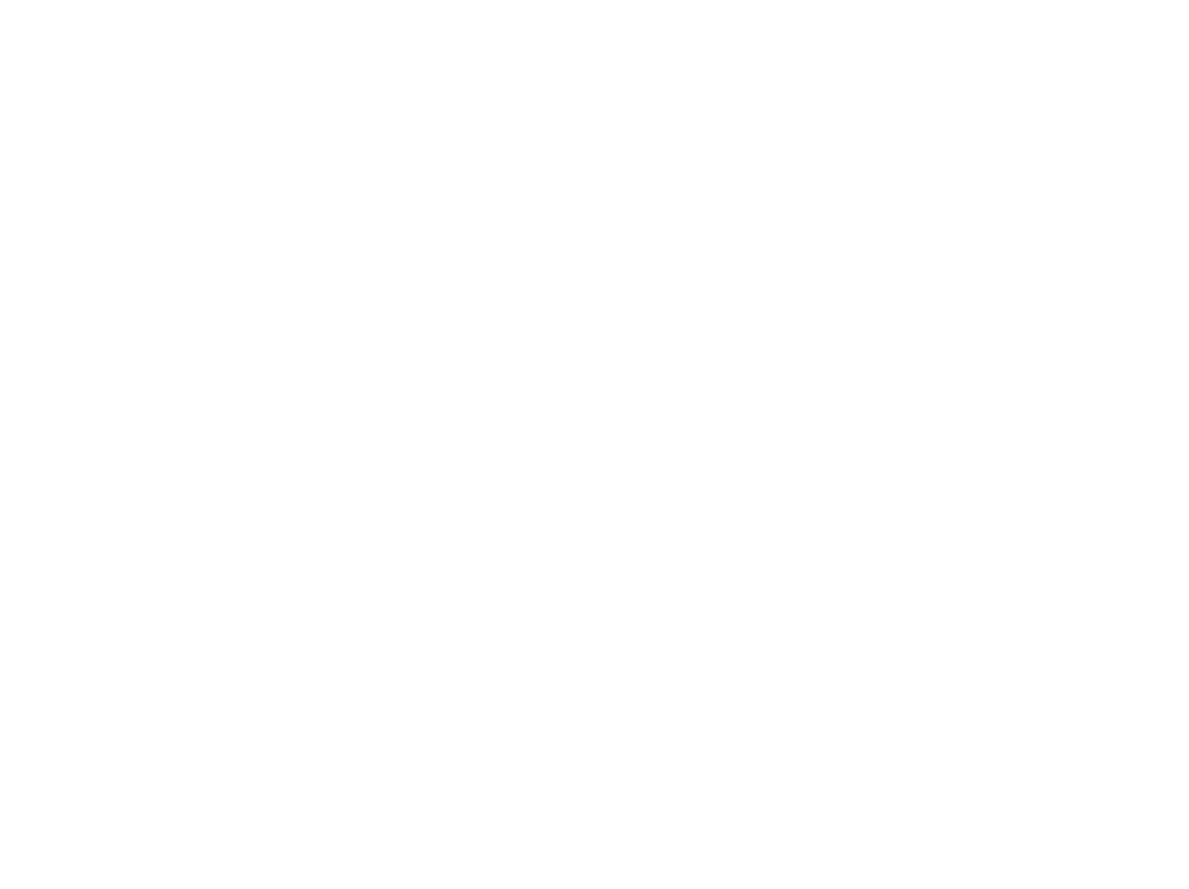

In [31]:
from collections import namedtuple


# text_lines is a list of text lines.
# Braille (converted with braille-converter:
# https://github.com/jpaugh/braille-converter.git).
text_lines = ["⠠ ⠋ ⠗ ⠑ ⠑ ⠠ ⠉ ⠠ ⠁ ⠠ ⠙"]
# See http://www.tiresias.org/research/reports/braille_cell.htm for examples
# of braille cell geometry.
horizontal_interdot = 2.5
vertical_interdot = 2.5
horizontal_intercell = 6
vertical_interline = 10
dot_height = 0.5
dot_diameter = 1.3

base_thickness = 1.5

# End of configuration.
BrailleCellGeometry = namedtuple(
    "BrailleCellGeometry",
    (
        "horizontal_interdot",
        "vertical_interdot",
        "intercell",
        "interline",
        "dot_height",
        "dot_diameter",
    ),
)


class Point(object):
    def __init__(self, x, y):
        self.x = x
        self.y = y

    def __add__(self, other):
        return Point(self.x + other.x, self.y + other.y)

    def __len__(self):
        return 2

    def __getitem__(self, index):
        return (self.x, self.y)[index]

    def __str__(self):
        return "({}, {})".format(self.x, self.y)


def brailleToPoints(text, cell_geometry):
    # Unicode bit pattern (cf. https://en.wikipedia.org/wiki/Braille_Patterns).
    mask1 = 0b00000001
    mask2 = 0b00000010
    mask3 = 0b00000100
    mask4 = 0b00001000
    mask5 = 0b00010000
    mask6 = 0b00100000
    mask7 = 0b01000000
    mask8 = 0b10000000
    masks = (mask1, mask2, mask3, mask4, mask5, mask6, mask7, mask8)

    # Corresponding dot position
    w = cell_geometry.horizontal_interdot
    h = cell_geometry.vertical_interdot
    pos1 = Point(0, 2 * h)
    pos2 = Point(0, h)
    pos3 = Point(0, 0)
    pos4 = Point(w, 2 * h)
    pos5 = Point(w, h)
    pos6 = Point(w, 0)
    pos7 = Point(0, -h)
    pos8 = Point(w, -h)
    pos = (pos1, pos2, pos3, pos4, pos5, pos6, pos7, pos8)

    # Braille blank pattern (u'\u2800').
    blank = "⠀"
    points = []
    # Position of dot1 along the x-axis (horizontal).
    character_origin = 0
    for c in text:
        for m, p in zip(masks, pos):
            delta_to_blank = ord(c) - ord(blank)
            if m & delta_to_blank:
                points.append(p + Point(character_origin, 0))
        character_origin += cell_geometry.intercell
    return points


def get_plate_height(text_lines, cell_geometry):
    # cell_geometry.vertical_interdot is also used as space between base
    # borders and characters.
    return (
        2 * cell_geometry.vertical_interdot
        + 2 * cell_geometry.vertical_interdot
        + (len(text_lines) - 1) * cell_geometry.interline
    )


def get_plate_width(text_lines, cell_geometry):
    # cell_geometry.horizontal_interdot is also used as space between base
    # borders and characters.
    max_len = max([len(t) for t in text_lines])
    return (
        2 * cell_geometry.horizontal_interdot
        + cell_geometry.horizontal_interdot
        + (max_len - 1) * cell_geometry.intercell
    )


def get_cylinder_radius(cell_geometry):
    """Return the radius the cylinder should have
    The cylinder have the same radius as the half-sphere make the dots (the
    hidden and the shown part of the dots).
    The radius is such that the spherical cap with diameter
    cell_geometry.dot_diameter has a height of cell_geometry.dot_height.
    """
    h = cell_geometry.dot_height
    r = cell_geometry.dot_diameter / 2
    return (r**2 + h**2) / 2 / h


def get_base_plate_thickness(plate_thickness, cell_geometry):
    """Return the height on which the half spheres will sit"""
    return (
        plate_thickness + get_cylinder_radius(cell_geometry) - cell_geometry.dot_height
    )


def make_base(text_lines, cell_geometry, plate_thickness):
    base_width = get_plate_width(text_lines, cell_geometry)
    base_height = get_plate_height(text_lines, cell_geometry)
    base_thickness = get_base_plate_thickness(plate_thickness, cell_geometry)
    base = cq.Workplane("XY").box(
        base_width, base_height, base_thickness, centered=False
    )
    return base


def make_embossed_plate(text_lines, cell_geometry):
    """Make an embossed plate with dots as spherical caps
    Method:
        - make a thin plate on which sit cylinders
        - fillet the upper edge of the cylinders so to get pseudo half-spheres
        - make the union with a thicker plate so that only the sphere caps stay
          "visible".
    """
    base = make_base(text_lines, cell_geometry, base_thickness)

    dot_pos = []
    base_width = get_plate_width(text_lines, cell_geometry)
    base_height = get_plate_height(text_lines, cell_geometry)
    y = base_height - 3 * cell_geometry.vertical_interdot
    line_start_pos = Point(cell_geometry.horizontal_interdot, y)
    for text in text_lines:
        dots = brailleToPoints(text, cell_geometry)
        dots = [p + line_start_pos for p in dots]
        dot_pos += dots
        line_start_pos += Point(0, -cell_geometry.interline)

    r = get_cylinder_radius(cell_geometry)
    base = (
        base.faces(">Z")
        .vertices("<XY")
        .workplane()
        .pushPoints(dot_pos)
        .circle(r)
        .extrude(r)
    )
    # Make a fillet almost the same radius to get a pseudo spherical cap.
    base = base.faces(">Z").edges().fillet(r - 0.001)
    hidding_box = cq.Workplane("XY").box(
        base_width, base_height, base_thickness, centered=False
    )
    result = hidding_box.union(base)
    return result


_cell_geometry = BrailleCellGeometry(
    horizontal_interdot,
    vertical_interdot,
    horizontal_intercell,
    vertical_interline,
    dot_height,
    dot_diameter,
)

if base_thickness < get_cylinder_radius(_cell_geometry):
    raise ValueError("Base thickness should be at least {}".format(dot_height))

result = make_embossed_plate(text_lines, _cell_geometry)
import sys
sys.modules.pop('primitives', None)
import primitives

from primitives import Cylinder, Node, GeometryScene, exporters
import importlib, primitives; importlib.reload(primitives)
from primitives import BambuPrintPipeline
import cadquery as cq
from primitives import exporters, BambuPrintPipeline
# Get the assembled model and rotate 90° around Y → stands upright

GeometryScene()

exporters.export(result, 'result.stl')


Cylinder 
 with L=40mm 
 and diameter=20mm
Threaded Cylinder 
 with L=20mm, thread M20 
 and chamfer 1x45
(0, Cylinder(40, 20)) (1, Thread())
[<matplotlib.lines.Line2D object at 0x123c3f460>, <matplotlib.lines.Line2D object at 0x123c8d0d0>]
plot_2d is called for Thread


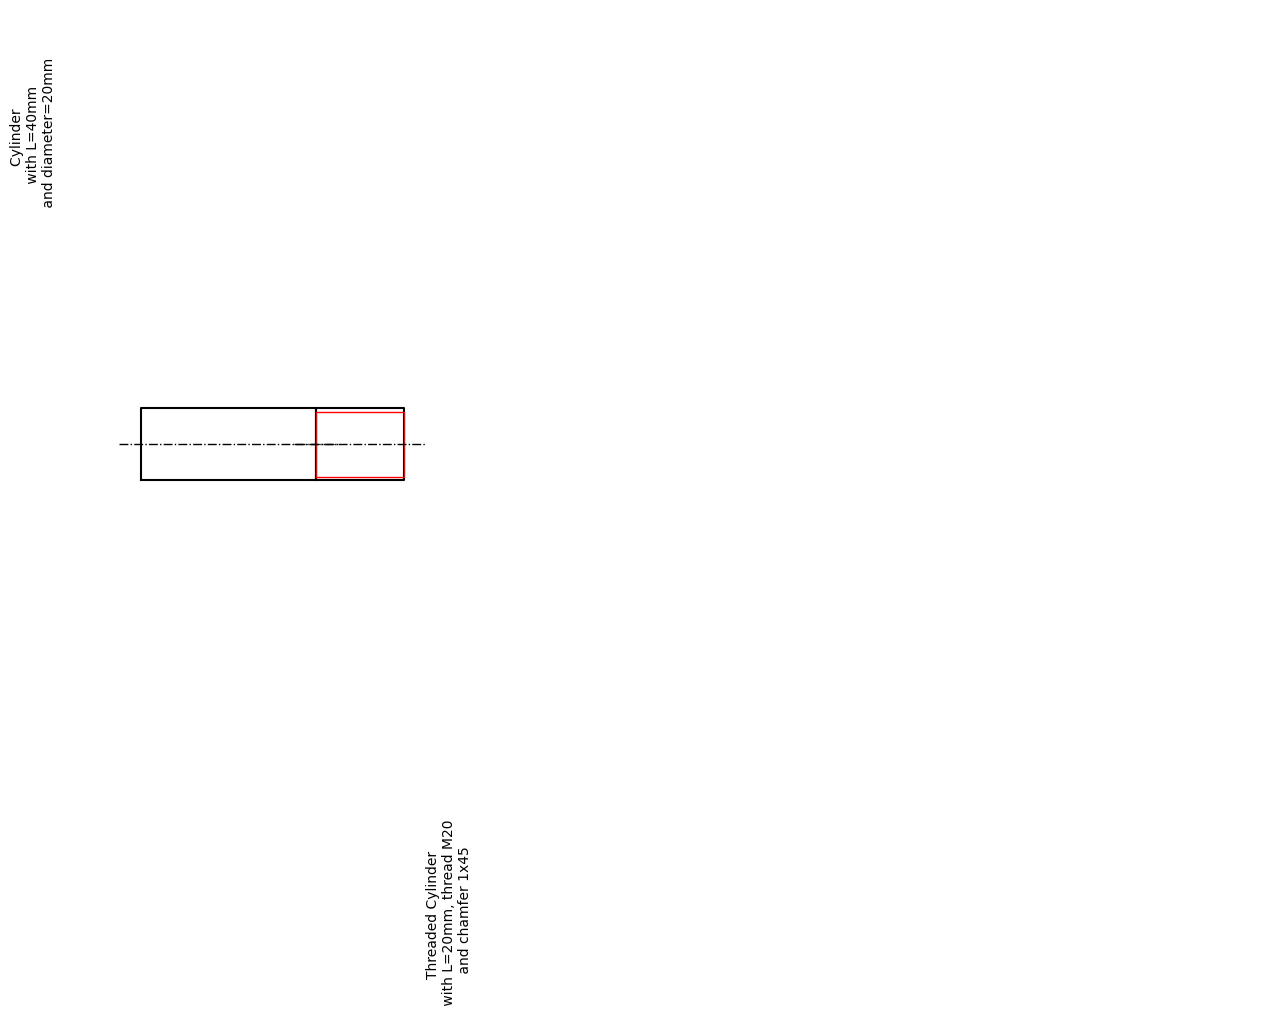

c


In [2]:
import importlib, primitives; importlib.reload(primitives)
from primitives import Cylinder, Thread, ComposedPart, GeometryScene, exporters
from primitives import ocp_show, ocp_set_port
import matplotlib.pyplot as plt

body = Cylinder(height=40, diameter=20)
thread = Thread(height=20, diameter=20, chamfer_length=1)
part = body + thread

print(body.str_en())
print(thread.str_en())

GeometryScene()
part.preview()
plt.show()

ocp_set_port(3939)
part.show_model(port=3939)

exporters.export(part.to_cq(), 'part.3mf')

